# Phase 12 — Final Model Selection

**Goal:** freeze the model, feature group, and tuned parameters based only on development-period evidence.

**Final holdout:** January–February 2017 remains protected and is not evaluated unless `RUN_FINAL_TRAINING = True` is explicitly enabled after all decisions are frozen.

**No trained model is saved or packaged by default.**

## 1. Load validation, feature, and tuning evidence

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path.cwd()
for candidate in [PROJECT_ROOT, *PROJECT_ROOT.parents]:
    if (candidate / "src" / "project_config.py").is_file():
        PROJECT_ROOT = candidate
        break
sys.path.insert(0, str(PROJECT_ROOT))

from src.project_config import *
from src.modeling_utils import *

import json
import numpy as np
import pandas as pd

comparison = pd.read_csv(PHASE9_COMPARISON) if PHASE9_COMPARISON.exists() else None
selected_model = None
best_params = {}

if not PHASE9_SELECTION.exists():
    raise FileNotFoundError("Run 09_model_comparison.ipynb first.")
selected_model = json.loads(PHASE9_SELECTION.read_text(encoding="utf-8"))["selected_model"]

if PHASE11_BEST_PARAMS.exists():
    payload = json.loads(PHASE11_BEST_PARAMS.read_text(encoding="utf-8"))
    if payload.get("selected_model") == selected_model:
        best_params = payload.get("best_params", {})

if comparison is not None:
    display(comparison.round(4))

print("Selected model:", selected_model)
print("Tuned parameters available:", bool(best_params))

,model,mean_validation_MAE,mean_validation_RMSE,mean_validation_R2,validation_RMSE_std,mean_train_RMSE,RMSE_train_to_validation_gap,baseline_mean_RMSE,RMSE_improvement_vs_baseline_pct
0,Random Forest,10.6524,22.1057,0.9231,2.4354,11.4512,10.6545,18.972,-16.5179
1,HistGradientBoosting,10.6685,22.2287,0.9222,2.2381,15.9860,6.2427,18.972,-17.1662
2,Decision Tree,13.7251,26.3039,0.8911,2.3386,13.1238,13.1801,18.972,-38.6462
3,Linear Regression,13.2784,26.3649,0.8906,2.0278,23.7472,2.6177,18.972,-38.9675


Selected model: Random Forest
Tuned parameters available: True


## 2. Prepare development data and protect the final test

In [2]:
if not FEATURE_DATA.exists():
    raise FileNotFoundError("Run 05_feature_engineering.ipynb first.")

features = pd.read_csv(FEATURE_DATA, parse_dates=["datetime", "target_datetime"])
history_features = (
    [f"PM2.5_lag_{x}h" for x in LAGS]
    + [f"PM2.5_roll_mean_{x}h" for x in ROLL_MEANS]
    + [f"PM2.5_roll_std_{x}h" for x in ROLL_STDS]
)

model_df = prepare_model_rows(features, TARGET, TARGET_TIME, history_features)
development = model_df[model_df[TARGET_TIME] <= pd.Timestamp("2016-12-31 23:00:00")].copy()
final_test = model_df[
    (model_df[TARGET_TIME] >= pd.Timestamp(FINAL_TEST_TARGET_START))
    & (model_df[TARGET_TIME] <= pd.Timestamp(FINAL_TEST_TARGET_END))
].copy()

if development.empty or final_test.empty:
    raise ValueError("Development or final test data is empty.")
if development[TARGET_TIME].max() >= final_test[TARGET_TIME].min():
    raise ValueError("Development data overlaps the protected final test period.")

DROP_COLUMNS = ["No", "datetime", "target_datetime", "has_next_hour", TARGET]

if not PHASE10_SELECTION.exists():
    raise FileNotFoundError("Run 10_feature_experiments.ipynb and complete all four experiments first.")

feature_payload = json.loads(PHASE10_SELECTION.read_text(encoding="utf-8"))
FINAL_FEATURES = feature_payload["feature_columns"]
missing_features = [c for c in FINAL_FEATURES if c not in development.columns]
if missing_features:
    raise ValueError(f"Selected Phase 10 features are missing: {missing_features}")

_, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS = model_input_columns(
    development, TARGET, feature_columns=FINAL_FEATURES
)

print("Development rows:", f"{len(development):,}")
print("Protected test rows:", f"{len(final_test):,}")
print("Final feature group:", feature_payload["selected_feature_group"])
print("Final feature count:", len(FINAL_FEATURES))
print("Final test period:", final_test[TARGET_TIME].min(), "to", final_test[TARGET_TIME].max())

Development rows: 345,348
Protected test rows: 14,827
Final feature group: D_all_including_rolling
Final feature count: 33
Final test period: 2017-01-01 00:00:00 to 2017-02-28 23:00:00


## 3. Freeze model and tuned parameters

In [3]:
FINAL_MODEL_NAME = selected_model
FINAL_MODEL = make_model(FINAL_MODEL_NAME)

# Apply Phase 11 parameters to the model object for inspection.
for parameter_name, parameter_value in best_params.items():
    clean_name = parameter_name.replace("model__", "")
    FINAL_MODEL.set_params(**{clean_name: parameter_value})

print("Final model:", FINAL_MODEL_NAME)
print("Tuned parameters:", best_params if best_params else "No tuning parameters; baseline model settings retained.")

Final model: Random Forest
Tuned parameters: {'model__n_estimators': 250, 'model__max_depth': 20.0, 'model__min_samples_leaf': 2}


## 4. Optional final training and one-time holdout evaluation — disabled by default

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RUN_FINAL_TRAINING = True

if RUN_FINAL_TRAINING:
    if not selected_model:
        raise ValueError("A validated Phase 9 model selection is required before final training.")

    final_pipeline = make_model_pipeline(
        FINAL_MODEL_NAME, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS
    )
    for parameter_name, parameter_value in best_params.items():

        if parameter_name in [
            "model__n_estimators",
            "model__max_depth",
            "model__min_samples_leaf"
        ]:
            if parameter_value is not None:
                parameter_value = int(parameter_value)

        final_pipeline.set_params(
            **{parameter_name: parameter_value}
    )

    X_dev = development[FINAL_FEATURES]
    y_dev = development[TARGET]
    X_test = final_test[FINAL_FEATURES]
    y_test = final_test[TARGET]

    final_pipeline.fit(X_dev, y_dev)
    test_pred = final_pipeline.predict(X_test)

    final_metrics = {
        "MAE": mean_absolute_error(y_test, test_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "R2": r2_score(y_test, test_pred),
    }

    print("FINAL 2017 HOLDOUT RESULTS")
    print(json.dumps(final_metrics, indent=2))
    print("Do not tune or alter the model after seeing these holdout results.")
else:
    print("Final training/evaluation disabled.")
    print("The 2017 holdout remains untouched.")

FINAL 2017 HOLDOUT RESULTS
{
  "MAE": 14.737498453924841,
  "RMSE": 34.12197266834677,
  "R2": 0.912073718665421
}
Do not tune or alter the model after seeing these holdout results.


## 5. Save the final decision record

In [5]:
RESULT_DIR.mkdir(parents=True, exist_ok=True)

final_selection_record = {
    "selected_model": FINAL_MODEL_NAME,
    "selected_feature_group": feature_payload["selected_feature_group"],
    "feature_columns": FINAL_FEATURES,
    "best_params": best_params,
    "selection_source": {
        "model_selection": "Phase 9 walk-forward validation",
        "feature_selection": "Phase 10 walk-forward validation",
        "hyperparameter_tuning": "Phase 11 walk-forward validation" if best_params else "No tuning performed",
    },
    "final_test_used_for_selection": False,
    "protected_test_period": [FINAL_TEST_TARGET_START, FINAL_TEST_TARGET_END],
}

PHASE12_SELECTION.write_text(
    json.dumps(final_selection_record, indent=2),
    encoding="utf-8",
)

print("Created:", PHASE12_SELECTION)

Created: /Users/ruchi/Documents/FDM_Mini_Project/data/results/phase12_final_model_selection.json


## Final rule

The 2017 January–February holdout is only for final generalisation testing after every model, feature, and hyperparameter decision has been frozen. The project does not save or package a trained model in this phase unless that is explicitly enabled by the user.

In [6]:
comparison_2017 = pd.DataFrame({
    "Actual_PM25": y_test.to_numpy(),
    "Predicted_PM25": test_pred
})

display(comparison_2017.head(20))

,Actual_PM25,Predicted_PM25
0,485.0,440.282461
1,477.0,388.882489
2,454.0,379.874530
3,418.0,382.806072
4,438.0,332.374007
5,453.0,382.387356
6,433.0,371.207673
7,416.0,362.165083
8,421.0,368.453687
9,424.0,358.558759


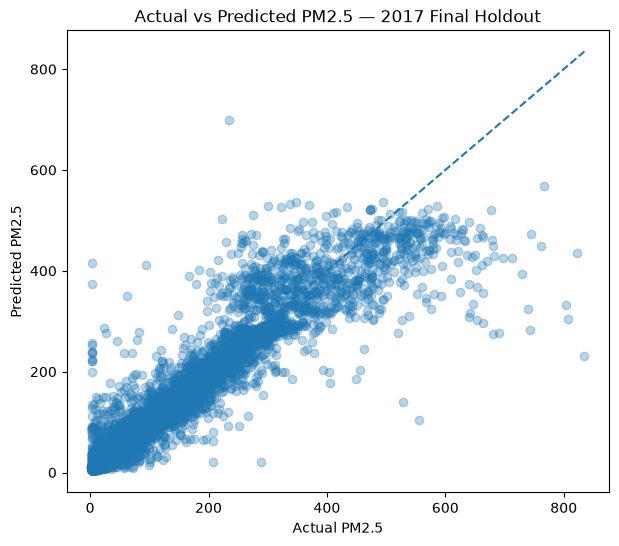

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_pred, alpha=0.3)

min_value = min(y_test.min(), test_pred.min())
max_value = max(y_test.max(), test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual PM2.5")
plt.ylabel("Predicted PM2.5")
plt.title("Actual vs Predicted PM2.5 — 2017 Final Holdout")
plt.show()

In [8]:
print("Final model parameters:")
print(final_pipeline.named_steps["model"].get_params())

Final model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 20, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 250, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [9]:
import joblib

# Make sure the results directory exists
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Save the complete fitted pipeline
FINAL_MODEL_PATH = RESULT_DIR / "final_pm25_pipeline.joblib"

joblib.dump(final_pipeline, FINAL_MODEL_PATH)

print("Final model saved successfully!")
print("Path:", FINAL_MODEL_PATH)
print("File exists:", FINAL_MODEL_PATH.exists())

Final model saved successfully!
Path: /Users/ruchi/Documents/FDM_Mini_Project/data/results/final_pm25_pipeline.joblib
File exists: True


In [10]:
# Reload the saved pipeline to verify the model artifact

loaded_pipeline = joblib.load(FINAL_MODEL_PATH)

print("Model loaded successfully!")
print("Model type:", type(loaded_pipeline))

print("\nRandom Forest parameters:")
print(loaded_pipeline.named_steps["model"].get_params())

Model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>

Random Forest parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 20, 'max_features': 1.0, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 2, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 250, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}


In [11]:
# Verify that the saved model can make predictions

loaded_test_pred = loaded_pipeline.predict(X_test)

print("Prediction successful!")
print("Number of predictions:", len(loaded_test_pred))
print("First 5 predictions:", loaded_test_pred[:5])

Prediction successful!
Number of predictions: 14827
First 5 predictions: [440.28246128 388.8824889  379.87453036 382.80607239 332.37400716]
